# Part 4 · Reservoir forecasts

## Navigation sketch

```text
Streamlit menu
├── Map & Overview  (default)
├── Explore & Quality
└── Forecast

Map & Overview ── selected region ──▶ Explore & Quality
Map & Overview ◀── region, dates and horizon ──▶ Forecast
```

Map & Overview combines the map, historical filling chart and NVE records. Explore & Quality contains reservoir quality, weather quality, correlation and transfers. Its analysis and transfer controls are local. Forecast uses the same historical dates and horizon as the map. All three pages share the selected area.

In [1]:
# Import the same code as Streamlit, from either the repository root or notebooks/.
from pathlib import Path
import sys

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from itertools import product
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from pymongo.errors import PyMongoError

from ind320.analysis.forecast import forecast_reservoir
from ind320.analysis.forecast_defaults import DEFAULT_ORDER, DEFAULT_TRAINING_WEEKS, DEFAULT_INPUTS
from ind320.data.areas import export_reservoir_geojson
from ind320.data.exchange import fetch_exchange_rates
from ind320.data.reservoirs import fetch_reservoir_history
from ind320.data.weather import fetch_weather
from ind320.data.weeks import (
    OSLO, WEEK, cutoff_time, reservoir_weeks, rolling_weather_correlation,
    weather_week_range, weekly_flows, weekly_fx, weekly_weather,
)
from ind320.storage.mongo_store import query_months

area = ("EL", 3)

2026-11-19 17:27:26.636 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 17:27:26.637 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


## Source dates and publication

A Sunday date labels each Norwegian ISO week. The interval runs from Monday
00:00 to next Monday 00:00 in Europe/Oslo. NVE normally publishes on Wednesday
at 13:00 local time. When the previous row names a plausible next release,
use that date as the schedule for the current row. Otherwise assume Wednesday.
Historical releases and revisions can differ from these estimates.

ENTSO-E reports UTC start and end instants. Calculate energy from the actual
interval duration, splitting intervals at Oslo week boundaries. Net import
uses one named border with both directions complete. Allow one hour from the
end of the week for the scheduled publication of its last flow interval.

Open-Meteo returns hourly UTC labels without an offset for this request. Weekly
temperature averages the hours in the Oslo week. Precipitation belongs to the
hour preceding its timestamp and is summed. The spring DST week has 167 hours,
and the autumn week has 169. Allow five days for ERA5 archive availability.

Norges Bank labels each business-day observation with a local date. Rates
become available around 16:00 Oslo time. A weekly FX value is the last
published quote, so weekends and holidays need no synthetic quotes.

[NVE handbook](https://webfileservice.nve.no/API/PublishedFiles/Download/64edbe40-b965-4c90-a114-88162ffff454/201903383/3435075) ·
[ENTSO-E data descriptions](https://eepublicdownloads.entsoe.eu/clean-documents/Transparency/MoP_Ref2_DDD_v3r4.pdf) ·
[Open-Meteo ERA5](https://open-meteo.com/en/docs/historical-weather-api) ·
[Norges Bank rates](https://www.norges-bank.no/en/topics/statistics/exchange_rates/valutakursar-faq/)

In [2]:
# Easter 2024 includes business days, holidays and the spring DST transition.
easter_rates = fetch_exchange_rates("2024-03-25", "2024-04-03")
assert set(easter_rates.pair) == {"EUR/NOK", "USD/NOK"}
display(easter_rates.pivot(index="date", columns="pair", values="nok_per_unit"))
display(weekly_fx(easter_rates))

# Compare NVE's date-only label and next-release field with the joined ISO week.
raw_nve = fetch_reservoir_history()
nve = reservoir_weeks(raw_nve)
region = nve.loc[nve["Area Type"].eq(area[0]) & nve["Area Code"].eq(area[1])]
display(region.loc[region.week.between("2024-03-24", "2024-04-07"),
                   ["Observation Date", "Iso Week", "Next Publication Date", "week", "available_at"]])
filling = region.set_index("week")["Fill Level"] * 100

pair,EUR/NOK,USD/NOK
date,,
2024-03-25,11.6050,10.7107
2024-03-26,11.6260,10.7103
2024-03-27,11.6825,10.8011
2024-04-02,11.7080,10.8922
2024-04-03,11.6580,10.8115


nok_per_unit              available_at
week       pair                                           
2024-03-31 EUR/NOK       11.6825 2024-03-27 16:00:00+01:00
           USD/NOK       10.8011 2024-03-27 16:00:00+01:00
2024-04-07 EUR/NOK       11.6580 2024-04-03 16:00:00+02:00
           USD/NOK       10.8115 2024-04-03 16:00:00+02:00

2026-11-19 17:27:26.866 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 17:27:26.867 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


,Observation Date,Iso Week,Next Publication Date,week,available_at
13718,2024-03-24,12,2024-04-03 13:00:00,2024-03-24,2024-03-27 13:00:00+01:00
13727,2024-03-31,13,2024-04-10 13:00:00,2024-03-31,2024-04-03 13:00:00+02:00
13736,2024-04-07,14,2024-04-17 13:00:00,2024-04-07,2024-04-10 13:00:00+02:00


In [3]:
# Compare a raw UTC ERA5 timestamp with its local week across the clock change.
# This public one-cell probe documents timestamp semantics. Area analysis below
# requires the full set of weighted cells.
response = requests.get(
    "https://archive-api.open-meteo.com/v1/archive",
    params={"latitude": 63.5, "longitude": 10.25, "start_date": "2024-03-24",
            "end_date": "2024-04-01", "timezone": "UTC", "models": "era5",
            "hourly": "temperature_2m,precipitation", "elevation": "nan",
            "cell_selection": "nearest"},
    timeout=30,
)
response.raise_for_status()
probe = pd.DataFrame(response.json()["hourly"])
display(probe.iloc[[0, 167, 168]])
probe.index = pd.to_datetime(probe.pop("time"), utc=True)
display(weekly_weather(probe))

,time,temperature_2m,precipitation
0,2024-03-24T00:00,-0.4,0.0
167,2024-03-30T23:00,4.2,0.0
168,2024-03-31T00:00,4.1,0.0


,temperature_2m,precipitation,available_at
week,,,
2024-03-31,4.180838,5.9,2024-04-06 00:00:00+02:00


In [4]:
# Read the published archive. A previous Part 2 local export can reproduce
# this comparison if Atlas is unavailable during notebook execution.
border = "NO3–SE2"
try:
    intervals = pd.concat([query_months(border, year, list(range(1, 13)))
                           for year in (2024, 2025)], ignore_index=True)
    flow_source = "MongoDB transfer_intervals"
except PyMongoError:
    intervals = pd.DataFrame()
    flow_source = "MongoDB unavailable"
saved_transfers = root / ".local" / "transfers.pkl"
if intervals.empty and saved_transfers.is_file():
    saved = pd.read_pickle(saved_transfers)
    intervals = saved.loc[saved.connection.eq(border)].copy()
    flow_source = "local Part 2 ENTSO-E archive export"

flow = weekly_flows(intervals)
print(f"{flow_source}. Complete weeks for {border}: {len(flow)}.")
if not intervals.empty:
    sample = intervals[["direction", "start", "end"]].head(2).copy()
    sample["start_oslo"] = sample.start.dt.tz_convert(OSLO)
    display(sample)
    display(flow.head(2))

MongoDB transfer_intervals. Complete weeks for NO3–SE2: 104.


,direction,start,end,start_oslo
0,export,2023-12-31 23:00:00+00:00,2024-01-02 09:00:00+00:00,2024-01-01 00:00:00+01:00
1,export,2024-01-02 09:00:00+00:00,2024-01-02 10:00:00+00:00,2024-01-02 10:00:00+01:00


,net_import_mwh,available_at
week,,
2024-01-07,5182.75,2024-01-08 01:00:00+01:00
2024-01-14,46589.24,2024-01-15 01:00:00+01:00


## Weekly River model and rolling backtest

NVE's native weekly resolution supplies a uniformly spaced target and gives
13 forecast dates over about three months. The model uses a 52-week seasonal
autoregressive term and learns chronologically. A single missing NVE week can
use the prior value for training. Scoring uses only observed target values.

Each optional input is joined with a lag and an availability timestamp. ERA5
is lagged by two weeks. FX and electricity flows are lagged by one week.
During forecasting, observed inputs are available only up to the forecast
origin. The last available weekly value supplies the rest of the forecast
as a persistence scenario. Actual weather, flows and rates beyond the cutoff
are reserved from model inputs.

Tuning uses the second Wednesday of January, April, July and September in 2023
and 2024. The same months in 2025 are held out until the setting is chosen.
Seasonal-naive takes the observed value 52 weeks earlier. Runtime excludes
source downloads and measures the fit plus the recursive forecast.

In [5]:
# Prepare sufficient FX history for the longest lookback and every origin.
fx = weekly_fx(fetch_exchange_rates("2019-12-01", "2025-12-31"))
sources = {pair: fx.xs(pair, level="pair").rename(columns={"nok_per_unit": pair})
           for pair in ("EUR/NOK", "USD/NOK")}

def origins(year):
    # W-WED generates the Wednesdays within each chosen calendar month.
    return [pd.date_range(f"{year}-{month:02d}-01", periods=2, freq="W-WED")[1]
            for month in (1, 4, 7, 9)]

def evaluate(dates, order, weeks, inputs=(), bands=False):
    # Refit from scratch at each cutoff and then join the future actuals.
    trials = []
    for origin in dates:
        cutoff = cutoff_time(origin)
        profile_start = perf_counter()
        predictions = forecast_reservoir(
            nve, sources, area=area, cutoff=cutoff, training_weeks=weeks,
            horizon=13, order=order, selected_inputs=inputs, intervals=bands,
        )
        elapsed_ms = (perf_counter() - profile_start) * 1000
        actual = filling.reindex(predictions.index)
        known = region.loc[region.available_at.le(cutoff)].set_index("week")["Fill Level"] * 100
        baseline = known.reindex(predictions.index - 52 * WEEK).to_numpy()
        trials.append(predictions.assign(actual=actual, seasonal_naive=baseline,
                                         origin=origin, runtime_ms=elapsed_ms))
    return pd.concat(trials)

def scores(trials, column):
    error = trials[column] - trials.actual
    return (error.abs().mean(), np.sqrt(error.pow(2).mean()))

tuning_dates = origins(2023) + origins(2024)
rows = []
for order, weeks, inputs in product(
    [(1, 1, 0), (4, 1, 0), (2, 1, 1)], [104, 156], [(), ("EUR/NOK", "USD/NOK")]
):
    trials = evaluate(tuning_dates, order, weeks, inputs)
    mae, rmse = scores(trials, "median")
    rows.append((order, weeks, inputs, mae, rmse, trials.runtime_ms.median()))
tuning = pd.DataFrame(rows, columns=["Order", "Weeks", "Inputs", "MAE (pp)", "RMSE (pp)", "Median ms"])
tuning = tuning.sort_values(["MAE (pp)", "Median ms"]).reset_index(drop=True)
display(tuning.round(2))
winner = tuning.iloc[0]
print("2023–24 seasonal-naive MAE and RMSE (pp):", np.round(scores(trials, "seasonal_naive"), 2))
print("App defaults:", winner.Order, winner.Weeks, winner.Inputs)
assert (winner.Order, int(winner.Weeks), winner.Inputs) == (DEFAULT_ORDER, DEFAULT_TRAINING_WEEKS, DEFAULT_INPUTS)

,Order,Weeks,Inputs,MAE (pp),RMSE (pp),Median ms
0,"(2, 1, 1)",156,"(EUR/NOK, USD/NOK)",7.96,13.84,6.99
1,"(1, 1, 0)",104,"(EUR/NOK, USD/NOK)",9.41,14.46,5.90
2,"(1, 1, 0)",156,"(EUR/NOK, USD/NOK)",11.22,16.54,6.43
3,"(2, 1, 1)",104,(),11.77,18.36,3.63
4,"(1, 1, 0)",104,(),12.42,18.21,3.70
5,"(2, 1, 1)",104,"(EUR/NOK, USD/NOK)",12.66,17.41,6.01
6,"(4, 1, 0)",104,"(EUR/NOK, USD/NOK)",12.87,16.70,5.80
7,"(2, 1, 1)",156,(),13.24,20.75,4.64
8,"(1, 1, 0)",156,(),14.52,20.17,4.32
9,"(4, 1, 0)",104,(),15.47,20.84,3.78


2023–24 seasonal-naive MAE and RMSE (pp): [7.09 9.58]
App defaults: (2, 1, 1) 156 ('EUR/NOK', 'USD/NOK')


## Forecast-interval bonus and held-out results

Fit the winning River SNARIMAX specification with quantile losses at 0.10,
0.50, and 0.90. Independently recurring paths can cross, so the band encloses
the median and both endpoints at each date. The result is a nominal 80%
prediction band conditional on the input scenario. Coverage below is
measured on held-out forecasts rather than inferred from the nominal level.

,MAE (pp),RMSE (pp)
River,6.61,8.15
Seasonal naive,16.72,20.53


Nominal 80% band: 71.2% coverage across 52 predictions, mean width 34.7 pp.
Crossing corrections: 3. Median interval-fit runtime: 13.3 ms.


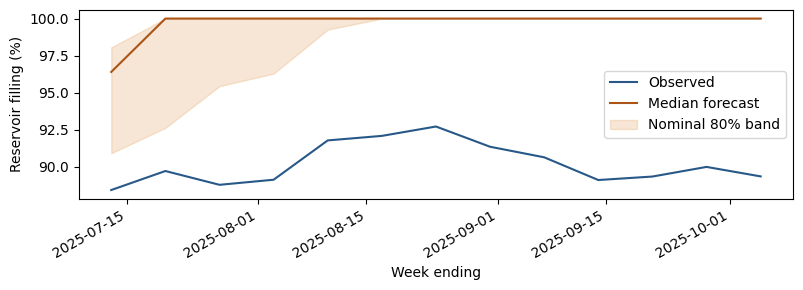

In [6]:
# The held-out dates enter only after selecting settings on the tuning dates.
holdout = evaluate(origins(2025), winner.Order, int(winner.Weeks), winner.Inputs, bands=True)
scored = holdout.dropna(subset=["actual"])
covered = scored.actual.between(scored.lower, scored.upper)
metrics = pd.DataFrame(
    [scores(scored, "median"), scores(scored, "seasonal_naive")],
    columns=["MAE (pp)", "RMSE (pp)"], index=["River", "Seasonal naive"],
)
display(metrics.round(2))
print(f"Nominal 80% band: {covered.mean():.1%} coverage across {len(scored)} predictions, "
      f"mean width {(scored.upper - scored.lower).mean():.1f} pp.")
print(f"Crossing corrections: {int(scored.crossed.sum())}. "
      f"Median interval-fit runtime: {scored.runtime_ms.median():.1f} ms.")

# Draw the held-out forecast with its uncertainty on the original fill scale.
example = holdout.loc[holdout.origin.eq(origins(2025)[2])]
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(example.index, example.actual, label="Observed", color="#285888")
ax.plot(example.index, example["median"], label="Median forecast", color="#aa5417")
ax.fill_between(example.index, example.lower, example.upper, alpha=0.22,
                color="#df9142", label="Nominal 80% band")
ax.set(ylabel="Reservoir filling (%)", xlabel="Week ending")
ax.legend(loc="best")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## Map geometry, optional inputs and rolling correlation

The national mainland footprint is a dissolve of the price boundaries. The
three water areas are approximations from grouped NVE administrative regions.
The export simplifies shared edges in metres before converting to WGS84.

For weather correlation, compare temperature or precipitation with weekly
change in reservoir filling. Positive lag means weather leads the change.
Compare positive and negative relationships over several windows rather
than using one coefficient as evidence of a physical effect.

In [7]:
# The runtime reads the generated GeoJSON and needs no GIS libraries.
geometry_path = root / "data" / "reservoir_areas.geojson"
export_reservoir_geojson(geometry_path)
import json
geometry = json.loads(geometry_path.read_text())
display(pd.Series([f["properties"]["area_type"] for f in geometry["features"]]).value_counts())

# Test complete matching past origins within the available archive.
optional_dates = [pd.Timestamp("2025-07-30"), pd.Timestamp("2025-08-27"),
                  pd.Timestamp("2025-09-24")]
optional_scores = []
if not flow.empty:
    sources["net_import_mwh"] = flow
    for inputs, name in [((), "NVE only"), (("net_import_mwh",), f"NVE and {border} net imports")]:
        sample = evaluate(optional_dates, winner.Order, 78, inputs)
        optional_scores.append((name, *scores(sample, "median")))
display(pd.DataFrame(optional_scores, columns=["Input comparison", "MAE (pp)", "RMSE (pp)"]).round(2))

EL      5
VASS    3
NO      1
Name: count, dtype: int64

,Input comparison,MAE (pp),RMSE (pp)
0,NVE only,4.83,6.72
1,NVE and NO3–SE2 net imports,6.15,7.40


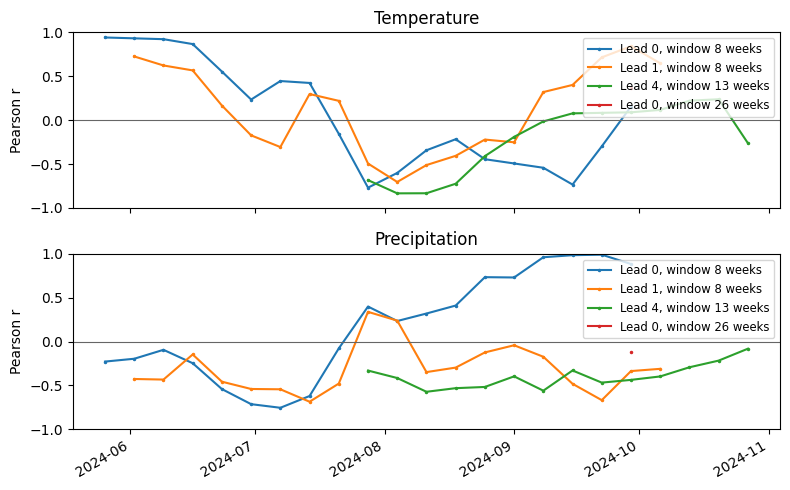

,Weather,Lead,Window,Windows observed,Min r,Max r
0,Temperature,0,8,19,-0.77,0.94
1,Temperature,1,8,19,-0.70,0.84
2,Temperature,4,13,14,-0.83,0.24
3,Temperature,0,26,1,0.37,0.37
4,Precipitation,0,8,19,-0.75,0.99
5,Precipitation,1,8,19,-0.69,0.34
6,Precipitation,4,13,14,-0.57,-0.08
7,Precipitation,0,26,1,-0.11,-0.11


In [8]:
# The full weighted NO3 download is resumable by cell. Keep this bounded
# window for correlation to limit the calls needed by the free archive.
try:
    area_hourly = fetch_weather("NO3", "2024-03-25", "2024-10-01")
    area_weeks = weekly_weather(area_hourly)
except requests.RequestException as error:
    area_weeks = pd.DataFrame()
    print(f"NO3 weather download incomplete ({type(error).__name__}). Cached cells can be reused.")
correlation_summary = pd.DataFrame()
if not area_weeks.empty:
    fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True, sharey=True)
    summaries = []
    for ax, (feature, label) in zip(axes, [
        ("temperature_2m", "Temperature"), ("precipitation", "Precipitation")
    ]):
        for lag, window in [(0, 8), (1, 8), (4, 13), (0, 26)]:
            corr = rolling_weather_correlation(filling, area_weeks[feature], lag, window).dropna()
            if not corr.empty:
                ax.plot(corr.index, corr, label=f"Lead {lag}, window {window} weeks", marker=".", ms=3)
                summaries.append((label, lag, window, len(corr), corr.min(), corr.max()))
        ax.set(title=label, ylabel="Pearson r", ylim=(-1, 1))
        ax.axhline(0, color="#666", lw=0.8)
        ax.legend(fontsize="small", loc="upper right")
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()
    correlation_summary = pd.DataFrame(summaries,
        columns=["Weather", "Lead", "Window", "Windows observed", "Min r", "Max r"])
    display(correlation_summary.round(2))

In [9]:
# Compare weather over the same 78-week runs when the archive supplies every week.
# A persistent weekly cache avoids rebuilding this long archive on each run.
first, last = pd.Timestamp("2024-01-21"), pd.Timestamp("2025-09-21")
weather_cache = root / ".local" / "part4-weather-training.csv"
try:
    if weather_cache.is_file():
        weather_fit = pd.read_csv(weather_cache, index_col="week", parse_dates=["week"])
        weather_fit["available_at"] = pd.to_datetime(weather_fit.available_at, utc=True)
    else:
        blocks = [
            (first, pd.Timestamp("2024-12-29")),
            (pd.Timestamp("2025-01-05"), last),
        ]
        weather_fit = pd.concat([weather_week_range("NO3", a, b) for a, b in blocks])
        weather_fit.to_csv(weather_cache)
    for feature in ["temperature_2m", "precipitation"]:
        sources[feature] = weather_fit
    cases = [(), ("temperature_2m", "precipitation")]
    comparison = [(" + ".join(inputs) or "NVE only",
                   *scores(evaluate(optional_dates, winner.Order, 78, inputs), "median")) for inputs in cases]
    display(pd.DataFrame(comparison, columns=["Inputs", "MAE (pp)", "RMSE (pp)"]).round(2))
except (requests.RequestException, ValueError) as error:
    print(f"Optional weather comparison could not run for {first.date()} through {last.date()}.")
    print(type(error).__name__, "· Cached ERA5 cells are reused on the next run.")

,Inputs,MAE (pp),RMSE (pp)
0,NVE only,4.83,6.72
1,temperature_2m + precipitation,8.96,11.08


## Compulsory work log

Part 4 starts with a three-page navigation sketch. The map and forecast
share the area, historical dates, and horizon. Explore & Quality reads the
same area while keeping its own year, weather and transfer controls. I
moved the reservoir trend next to the table so that examining a series and
inspecting the underlying observations use the same selection. The water
polygons represent grouped NVE administrative areas. That approximation
is marked on the map and affects the interpretation of weather averages.

The notebook shows how the same calendar week appears in four sources.
Magasinstatistikk dates label observations, while NVE publication happens
later. An ENTSO-E interval is a pair of UTC instants. Open-Meteo
precipitation describes the preceding hour and its ERA5 archive arrives
with a delay. Norges Bank publishes FX quotes on business days. Aligning
all four made it possible to filter historical forecast inputs by what
was available on the forecast date. The historical API snapshots can
include revisions, so publication times remain assumptions for the
rolling backtest.

I compared River configurations using 13-week forecasts at several
historical cutoffs. The benchmark tables show error in percentage points,
fit-and-forecast runtime, and a separate seasonal-naive reference.
On held-out 2025 origins the chosen River model had 6.61 percentage points
of MAE, compared with 16.72 for seasonal-naive. Streamlit uses the chosen
156-week lookback, order (2, 1, 1), and both FX series as defaults. The interval bonus replaces the single
prediction path with a median and a shaded band derived from River
quantile loss. The band covered 71.2% of held-out
observations, so it fell short of its nominal 80% coverage.

In Jupyter I could inspect coverage and compare lags directly. In
Streamlit the same results need labels, clear empty states, and controls
that survive navigation. For NO3 in 2024, the 8-week temperature correlation with no lag ranged
from −0.77 to 0.94. A four-week lead on a 13-week window had substantial
negative periods for both weather variables, and the 26-week window gave
only one estimate in this sample. The changes support testing weather lags
on matched forecast dates. They also show how sensitive a short-window
coefficient can be to which weeks it includes. Cold archive downloads
make the Streamlit cache useful when comparing map dates and properties.

[Public GitHub repository](https://github.com/dared22/ind320) ·
[Streamlit app](https://cklqlkatpe9mqyrnuch2ma.streamlit.app/)

## AI-tool use

I used Codex to help implement the API adapters, date alignment, River
backtest, Streamlit pages, tests, and notebook export. I am responsible for
reviewing the assumptions and explaining the results.